# Segmented mirrors: hexagons, spikes and phasing

A monolithic mirror much larger than 8 m cannot be cast, polished, carried
or launched. The Keck telescopes (10 m, 36 segments), the Gran Telescopio
Canarias, the James Webb Space Telescope (6.5 m, 18 segments) and the
coming 25–40 m telescopes therefore assemble their primaries from
hexagonal segments. A segmented mirror is a telescope only once all the
segments form one continuous surface to a small fraction of a
wavelength; before that it is an array of small telescopes whose images
merely overlap.

This notebook builds a JWST-like aperture with `pyoptics.segmented` and
covers:

1. the diffraction pattern of one hexagon, against the closed form
   Fourier transform of a polygon, and why it has six spikes,
2. the whole aperture: the segment PSF times the array factor, and the
   struts of the secondary mirror that add the two horizontal spikes of
   the famous 6 + 2 pattern,
3. segment piston errors: the Strehl ratio against the exact on-axis sum
   and against $e^{-\sigma^2}$, and the halo of segment PSFs that random
   pistons scatter light into,
4. segment tip-tilt errors: from a slightly blurred image to the 18
   separate images seen at the start of JWST's commissioning,
5. coarse phasing with a dispersed fringe sensor: two segments, a grism,
   fringes whose number across the spectrum is the piston difference,
   and the capture range,
6. fine phasing by phase retrieval from defocused images (multi-plane
   Gerchberg–Saxton), the fit of segment piston and tip-tilt, a closed
   correction loop, and the wrapping ambiguity that makes coarse phasing
   necessary.

Notebook 28 covers phase retrieval in general, notebook 74 interferometry
between separate telescopes (the same fringes, with kilometre baselines),
notebook 96 coronagraphs, for which segment gaps and spikes are the
main nuisance. Lengths are in metres, angles in radians unless stated.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from pyoptics import segmented as sg
from pyoptics import sketch
from pyoptics.coronagraph import mft, pupil_grid

t_start = time.time()
lam = 2.0e-6                    # NIRCam-like phasing wavelength
mas = np.pi/180/3600/1000       # milliarcsecond

## The setups

Phasing needs light from a star and a way to compare segments. The
**dispersed fringe sensor** (coarse phasing, for steps of micrometres to
tens of micrometres) masks the pupil down to two neighbouring segments
and disperses their image with a grism: each wavelength shows two-beam
fringes, and their phase changes across the spectrum in proportion to
the piston step. **Phase retrieval** (fine phasing, below a wavelength)
records images through weak lenses of known defocus and computes the
pupil phase from them.

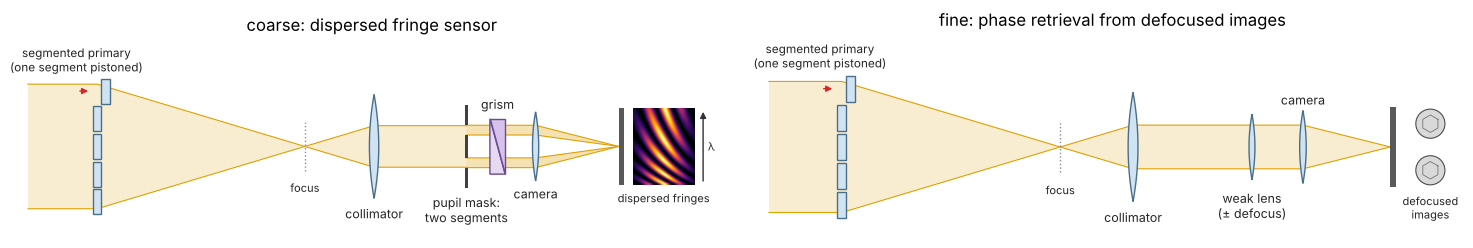

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8))
sketch.segment_phasing_layout(axs[0], "dfs", title="coarse: dispersed fringe sensor")
sketch.segment_phasing_layout(axs[1], "pr", title="fine: phase retrieval from defocused images")
plt.tight_layout()
plt.show()

## 1. The aperture and one hexagon

18 segments of 1.32 m flat-to-flat with 7 mm gaps in two rings around an
empty centre, three struts of 10 cm width holding the secondary
mirror. The grid has 512 samples over 6.8 m (13 mm per pixel; the edges
are antialiased by subsampling).

segments: 18, segment area 1.5090 m^2 (grid 1.5101), collecting area 26.44 m^2
struts block 2.61 % of it
outer diameter (vertex to vertex) 6.67 m


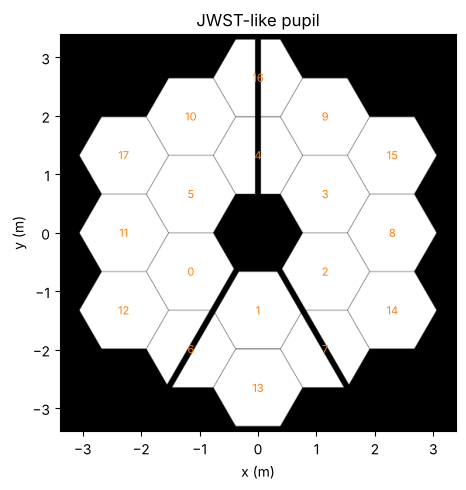

In [3]:
x = pupil_grid(512, 6.8)
dx = x[1] - x[0]
P = sg.jwst_like_pupil(x, x)
seg_area = np.sqrt(3)/2*P.flat**2
print("segments: %d, segment area %.4f m^2 (grid %.4f), collecting area %.2f m^2"
      % (len(P.centres), seg_area, P.masks[0].sum()*dx**2, P.pupil.sum()*dx**2))
print("struts block %.2f %% of it" % (100*np.sum(P.masks.sum(0)*(1 - P.struts))/np.sum(P.masks)))
r_max = np.max([np.max(np.hypot(*sg.hexagon_vertices(c, P.flat).T)) for c in P.centres])
print("outer diameter (vertex to vertex) %.2f m" % (2*r_max))

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(P.pupil, extent=(x[0], x[-1], x[0], x[-1]), origin="lower", cmap="gray")
for k, c in enumerate(P.centres):
    ax.text(c[0], c[1], str(k), ha="center", va="center", color="C1", fontsize=8)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("JWST-like pupil")
plt.tight_layout()
plt.show()

The far field of one hexagon is its Fourier transform. By the divergence
theorem, the integral of $e^{-i\mathbf{k}\cdot\mathbf{r}}$ over a polygon
becomes a sum over its edges (`polygon_ft()`):

$$F(\mathbf{k}) = \sum_j \frac{i\,\mathbf{k}\cdot\mathbf{n}_j}{k^2}\,L_j\,
e^{-i\mathbf{k}\cdot\mathbf{m}_j}\,\operatorname{sinc}\frac{\mathbf{k}\cdot\mathbf{e}_j}{2}$$

(normals $\mathbf{n}_j$, lengths $L_j$, midpoints $\mathbf{m}_j$, edge vectors
$\mathbf{e}_j$). In a generic direction every term decays like $1/k$
times a sinc, so the intensity falls as $k^{-4}$; along an edge normal
the sinc of that edge (and of the opposite one) is 1 and the intensity
falls only as $k^{-2}$. The six spikes of a hexagon point along the normals
of its three pairs of parallel edges. The matrix Fourier transform of
the sampled hexagon against the formula:

max deviation MFT - closed form: 1.8e-04 of the peak


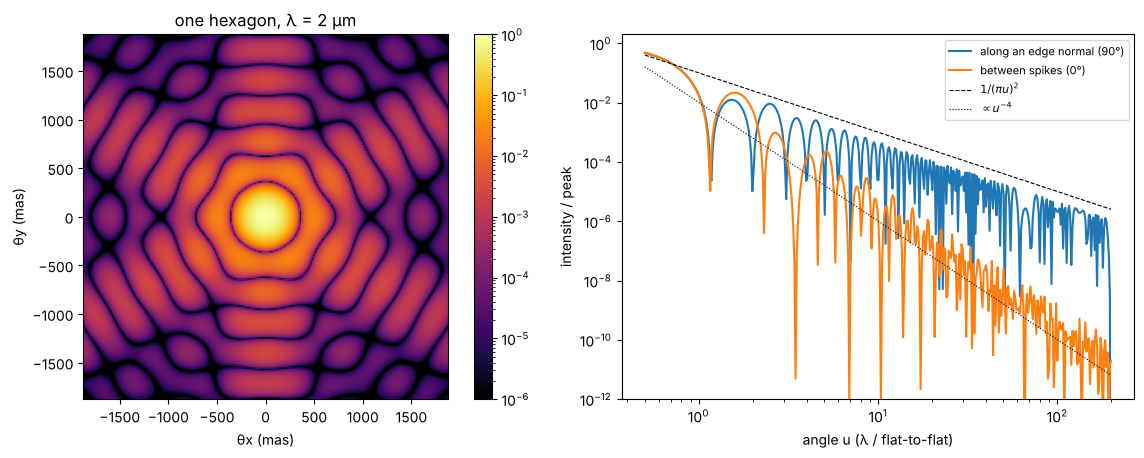

In [4]:
V0 = sg.hexagon_vertices((0, 0), P.flat)
xh = pupil_grid(256, 1.6)
H = sg.polygon_mask(xh, xh, V0, 8)
th = np.linspace(-6, 6, 241)*lam/P.flat           # +-6 lambda/flat
T, S = np.meshgrid(th, th)
k = 2*np.pi/lam
F_num = sg.far_field(H, xh, xh, th, th, lam)
F_ana = sg.polygon_ft(V0, k*T, k*S)/lam
print("max deviation MFT - closed form: %.1e of the peak" % (np.abs(F_num - F_ana).max()/np.abs(F_ana).max()))

I_h = np.abs(F_ana/F_ana.max())**2
r = np.geomspace(0.5, 200, 400)*lam/P.flat
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
im = axs[0].imshow(I_h, extent=np.array([th[0], th[-1], th[0], th[-1]])/mas, origin="lower",
                   norm=LogNorm(1e-6, 1), cmap="inferno")
plt.colorbar(im, ax=axs[0])
axs[0].set_xlabel("θx (mas)")
axs[0].set_ylabel("θy (mas)")
axs[0].set_title("one hexagon, λ = 2 µm")
for ang, lab in ((np.pi/2, "along an edge normal (90°)"), (0.0, "between spikes (0°)")):
    Fr = sg.polygon_ft(V0, k*r*np.cos(ang), k*r*np.sin(ang))
    axs[1].loglog(r/(lam/P.flat), np.abs(Fr/(np.sqrt(3)/2*P.flat**2))**2, label=lab)
rr = r/(lam/P.flat)
axs[1].loglog(rr, 1/(np.pi**2*rr**2), "k--", lw=0.8, label=r"$1/(\pi u)^2$")
axs[1].loglog(rr, 1/(np.pi**4*rr**4), "k:", lw=0.8, label=r"$\propto u^{-4}$")
axs[1].set_ylim(1e-12, 2)
axs[1].set_xlabel("angle u (λ / flat-to-flat)")
axs[1].set_ylabel("intensity / peak")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Along a spike the intensity follows $1/(\pi u)^2$ times an oscillating
factor (the two parallel edges a flat-to-flat width apart form a slit),
between the spikes it drops as $u^{-4}$, four orders of magnitude lower at
$u = 100$.

## 2. The whole aperture: array factor and struts

Identical segments at the centres $\mathbf{c}_j$ give the far field of
one segment times the array factor $\sum_j e^{-i\mathbf{k}\cdot\mathbf{c}_j}$.
The array factor is the PSF of 18 points: a central peak of width
$\lambda/D$ and grating peaks at the reciprocal lattice of the segment
pitch $p$, $2\lambda/(\sqrt{3}\,p)$ away, which fall close to the first
zeros of the segment PSF and are suppressed by it. Without struts the
product is exact:

segment PSF x array factor, max deviation: 4.4e-04 of the peak
grating peaks at 2 lambda/(sqrt 3 p) = 359.0 mas, first zero of the segment ~ 312.5 mas


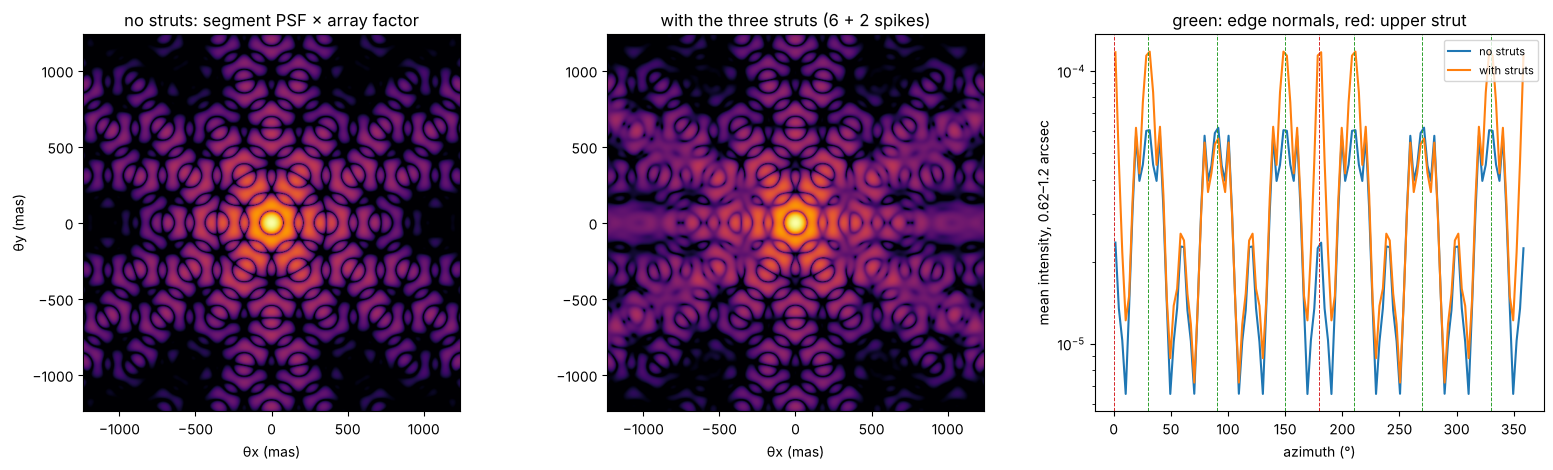

In [5]:
th = np.linspace(-6, 6, 601)*1e-6             # +-6 µrad = +-1.24 arcsec
T, S = np.meshgrid(th, th)
F = sg.far_field(P.masks.sum(0), x, x, th, th, lam)
F_ana = sg.polygon_ft(V0, k*T, k*S)*sg.array_factor(P.centres, k*T, k*S)/lam
print("segment PSF x array factor, max deviation: %.1e of the peak"
      % (np.abs(F - F_ana).max()/np.abs(F_ana).max()))
pitch = P.flat + 0.007
print("grating peaks at 2 lambda/(sqrt 3 p) = %.1f mas, first zero of the segment ~ %.1f mas"
      % (2*lam/(np.sqrt(3)*pitch)/mas, lam/P.flat/mas))

E0 = sg.segment_field(P, x, x, lam)
F0 = sg.far_field(E0, x, x, th, th, lam)
I0 = np.abs(F0)**2
peak = I0.max()
I0 /= peak
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
ext = np.array([th[0], th[-1], th[0], th[-1]])/mas
axs[0].imshow(np.abs(F_ana)**2/np.abs(F_ana).max()**2, extent=ext, origin="lower",
              norm=LogNorm(1e-6, 1), cmap="inferno")
axs[0].set_title("no struts: segment PSF × array factor")
axs[1].imshow(I0, extent=ext, origin="lower", norm=LogNorm(1e-6, 1), cmap="inferno")
axs[1].set_title("with the three struts (6 + 2 spikes)")
for ax in axs[:2]:
    ax.set_xlabel("θx (mas)")
axs[0].set_ylabel("θy (mas)")
# azimuthal profile in an annulus
R = np.hypot(T, S)
A = np.degrees(np.arctan2(S, T)) % 360
ring = (R > 3e-6) & (R < 5.8e-6)
bins = np.arange(0, 361, 3)
for img, lab in ((np.abs(F_ana)**2/np.abs(F_ana).max()**2, "no struts"), (I0, "with struts")):
    prof = np.array([img[ring & (A >= a) & (A < a + 3)].mean() for a in bins[:-1]])
    axs[2].semilogy(bins[:-1] + 1.5, prof, label=lab)
for a in range(30, 360, 60):
    axs[2].axvline(a, color="C2", lw=0.7, ls="--")
for a in (0, 180):
    axs[2].axvline(a, color="C3", lw=0.7, ls="--")
axs[2].set_xlabel("azimuth (°)")
axs[2].set_ylabel("mean intensity, 0.62–1.2 arcsec")
axs[2].set_title("green: edge normals, red: upper strut")
axs[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

The six spikes of the segments point along the edge normals of the
hexagons (30°, 90°, 150°, ...; dashed green). A strut diffracts
perpendicular to itself: the two lower struts (at 240° and 300°) run
perpendicular to edges, so their spikes fall on four of the six hexagon
spikes and make them brighter than the vertical pair; the upper strut
(at 90°) adds the horizontal pair at 0° and 180° (dashed red), which is
absent without struts. That is the 6 + 2 pattern of JWST images.

## 3. Segment piston errors

A piston $p_j$ multiplies the field of segment $j$ by $e^{2\pi i p_j/\lambda}$.
On the axis the segment fields add as phasors, so the Strehl ratio is
exactly

$$S = \frac{\left|\sum_j A_j e^{2\pi i p_j/\lambda}\right|^2}{\left(\sum_j A_j\right)^2}$$

with the open areas $A_j$, which for small errors is close to the Maréchal
$e^{-\sigma^2}$ with the rms phase $\sigma$ over the pupil. Random sets of
pistons, Strehl from the far field, the sum and $e^{-\sigma^2}$:

In [6]:
rng = np.random.default_rng(1)
A_seg = (P.masks*P.struts).sum((1, 2))
n_seg = len(P.centres)
F_ref = sg.far_field(E0, x, x, [0.0], [0.0], lam)[0, 0]
rows = []
z = rng.normal(0, 1, n_seg)
for rms_nm in (20, 50, 100, 150, 200, 300):
    p = z*rms_nm*1e-9
    E = sg.segment_field(P, x, x, lam, piston=p)
    S_ff = np.abs(sg.far_field(E, x, x, [0.0], [0.0], lam)[0, 0]/F_ref)**2
    S_sum = np.abs(np.sum(A_seg*np.exp(2j*np.pi*p/lam)))**2/A_seg.sum()**2
    sig = 2*np.pi/lam*np.sqrt(np.average((p - np.average(p, weights=A_seg))**2, weights=A_seg))
    rows.append((rms_nm, sig, S_ff, S_sum, np.exp(-sig**2)))
print("%10s %10s %12s %12s %12s" % ("rms (nm)", "sigma", "far field", "phasor sum", "exp(-s^2)"))
for r_ in rows:
    print("%10d %10.3f %12.4f %12.4f %12.4f" % r_)

  rms (nm)      sigma    far field   phasor sum    exp(-s^2)
        20      0.036       0.9987       0.9987       0.9987
        50      0.089       0.9920       0.9920       0.9920
       100      0.179       0.9685       0.9685       0.9685
       150      0.268       0.9305       0.9305       0.9305
       200      0.358       0.8797       0.8797       0.8798
       300      0.537       0.7496       0.7496       0.7496


What happens to the light? For independent random pistons of rms phase
$\sigma$ the mean intensity is (cross terms between segments average to
$e^{-\sigma^2}$)

$$\langle I\rangle = |F_\mathrm{seg}|^2\left[e^{-\sigma^2}\,|AF|^2 + (1 - e^{-\sigma^2})\,N\right]:$$

the coherent PSF shrinks by $e^{-\sigma^2}$, and the rest goes into a
halo with the shape of a single segment's PSF, $D/\text{flat} \approx 5$
times wider than the telescope's. Averaged over 40 realizations at
$\sigma = 1$ rad (no struts, for the comparison):

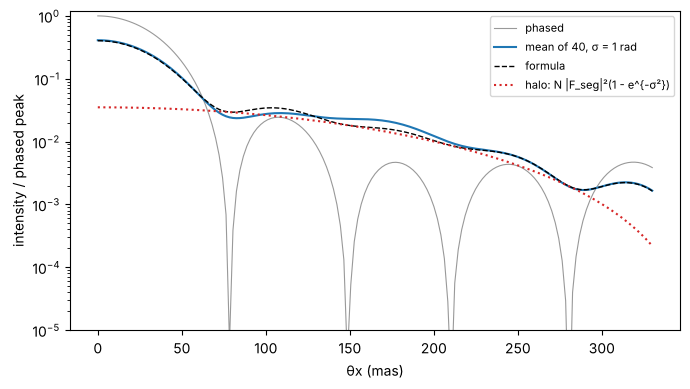

Strehl: mean 0.410, formula exp(-1) + (1 - exp(-1))/N = 0.403


In [7]:
sig_t = 1.0
p_rms = sig_t*lam/(2*np.pi)
th_c = np.linspace(0, 1.6e-6, 161)
Pn = sg.SegmentedPupil(P.masks, P.centres, P.flat, P.angle, np.ones_like(P.struts), P.masks.sum(0))
acc = np.zeros(len(th_c))
n_real = 40
for _ in range(n_real):
    p = rng.normal(0, p_rms, n_seg)
    E = sg.segment_field(Pn, x, x, lam, piston=p)
    acc += np.abs(sg.far_field(E, x, x, th_c, [0.0], lam)[0])**2
acc /= n_real
Fs = sg.polygon_ft(V0, k*th_c, 0*th_c)/lam
AF = sg.array_factor(P.centres, k*th_c, 0*th_c)
model = np.abs(Fs)**2*(np.exp(-sig_t**2)*np.abs(AF)**2 + (1 - np.exp(-sig_t**2))*n_seg)
norm = np.abs(Fs[0]*n_seg)**2
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(th_c/mas, np.abs(Fs*AF)**2/norm, color="0.6", lw=0.8, label="phased")
ax.semilogy(th_c/mas, acc/norm, label="mean of %d, σ = 1 rad" % n_real)
ax.semilogy(th_c/mas, model/norm, "k--", lw=1, label="formula")
ax.semilogy(th_c/mas, np.abs(Fs)**2*n_seg*(1 - np.exp(-sig_t**2))/norm, ":", color="C3",
            label="halo: N |F_seg|²(1 - e^{-σ²})")
ax.set_ylim(1e-5, 1.2)
ax.set_xlabel("θx (mas)")
ax.set_ylabel("intensity / phased peak")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Strehl: mean %.3f, formula exp(-1) + (1 - exp(-1))/N = %.3f"
      % (acc[0]/norm, np.exp(-1) + (1 - np.exp(-1))/n_seg))

## 4. Segment tip-tilt errors

A wavefront tilt $\mathbf{t}_j$ (radians) of a segment moves its image by
$\mathbf{t}_j$. On the axis it contributes the transform of its hexagon at
$\mathbf{k} = -2\pi\mathbf{t}_j/\lambda$, which again gives the exact Strehl
ratio. The rms phase of a tilt over a hexagon is $k\,t\,r_\mathrm{rms}/
\sqrt{2}$ per component, with $r_\mathrm{rms} = \sqrt{5/12}\,s$ for the side
$s$ (`hexagon_rms_radius()`), so random tilts of rms $t$ per axis give
$\sigma = k\,t\,r_\mathrm{rms}$ and $S \approx e^{-\sigma^2}$:

In [8]:
r_rms = sg.hexagon_rms_radius(P.flat)
print("r_rms = %.4f m" % r_rms)
print("%12s %10s %12s %14s %12s" % ("t rms (mas)", "sigma", "far field", "hexagon sum", "exp(-s^2)"))
za, zb = rng.normal(0, 1, n_seg), rng.normal(0, 1, n_seg)
for t_mas in (5, 10, 20, 40):
    t = t_mas*mas
    a, b = za*t, zb*t
    E = sg.segment_field(Pn, x, x, lam, tip=a, tilt=b)
    E0n = sg.segment_field(Pn, x, x, lam)
    S_ff = np.abs(sg.far_field(E, x, x, [0.0], [0.0], lam)[0, 0]/sg.far_field(E0n, x, x, [0.0], [0.0], lam)[0, 0])**2
    S_hex = np.abs(np.sum(sg.polygon_ft(V0, -k*a, -k*b)))**2/(n_seg*np.sqrt(3)/2*P.flat**2)**2
    sig = k*r_rms*np.sqrt(np.mean(a**2 + b**2)/2)
    print("%12d %10.3f %12.4f %14.4f %12.4f" % (t_mas, sig, S_ff, S_hex, np.exp(-sig**2)))

r_rms = 0.4919 m
 t rms (mas)      sigma    far field    hexagon sum    exp(-s^2)
           5      0.034       0.9988         0.9988       0.9988
          10      0.068       0.9954         0.9954       0.9954
          20      0.136       0.9816         0.9816       0.9816
          40      0.272       0.9287         0.9286       0.9285


When the segments of JWST were first deployed they were far from their
final positions: the camera saw 18 separate, blurred images of the same
star, scattered over the field. The first steps of
commissioning (segment image identification, then image stacking) found
which image belongs to which segment by moving them one by one, and
pointed all of them at the same spot. Below, the 18 images for random
tilts of 1.5 arcseconds, and the same images stacked (tilts removed) but not yet
phased (random pistons of 1 µm): one bright core made of the incoherent
sum of the segment PSFs, without the fine structure of the full aperture.

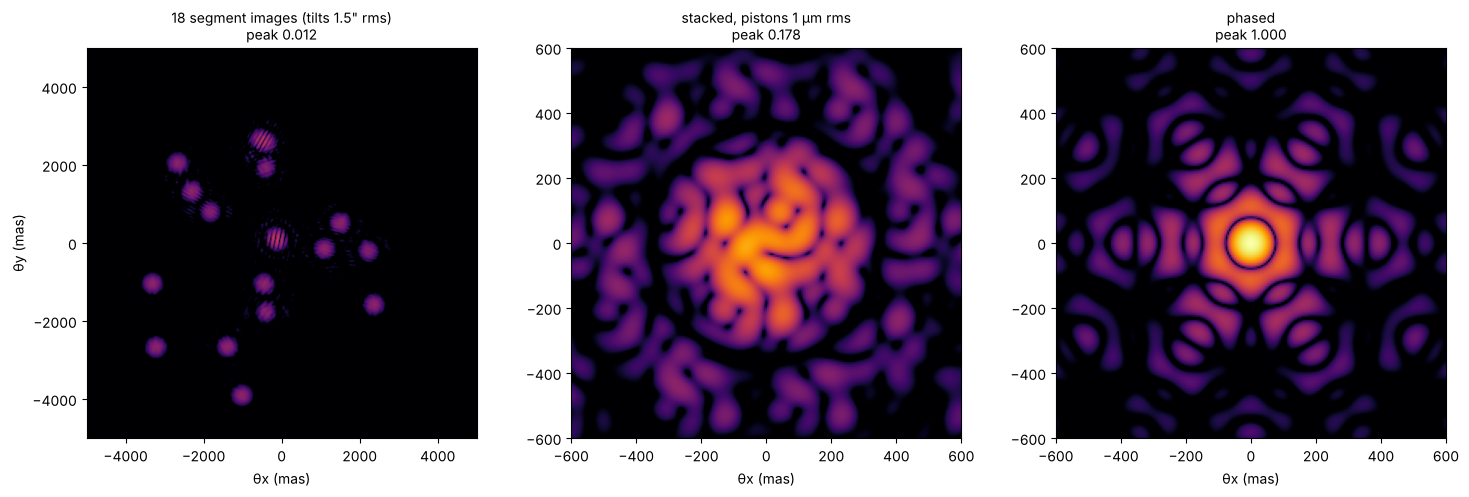

In [9]:
arcsec = 1000*mas
a, b = rng.normal(0, 1.5*arcsec, n_seg), rng.normal(0, 1.5*arcsec, n_seg)
cases = [("18 segment images (tilts 1.5\" rms)", dict(tip=a, tilt=b), 5*arcsec, 401),
         ("stacked, pistons 1 µm rms", dict(piston=rng.normal(0, 1e-6, n_seg)), 0.6*arcsec, 241),
         ("phased", dict(), 0.6*arcsec, 241)]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (title, kw, half, n_th) in zip(axs, cases):
    th_l = np.linspace(-half, half, n_th)
    E = sg.segment_field(P, x, x, lam, **kw)
    I = np.abs(sg.far_field(E, x, x, th_l, th_l, lam))**2/peak
    ax.imshow(I, extent=np.array([th_l[0], th_l[-1], th_l[0], th_l[-1]])/mas, origin="lower",
              norm=LogNorm(1e-4, 1), cmap="inferno")
    ax.set_title("%s\npeak %.3f" % (title, I.max()), fontsize=10)
    ax.set_xlabel("θx (mas)")
axs[0].set_ylabel("θy (mas)")
plt.tight_layout()
plt.show()

A single segment's image has a peak of $1/18^2 = 0.003$ of the phased
telescope's, the stacked but unphased image about $1/18$ (the intensities
add), and only phasing brings the remaining factor of 18.

## 5. Coarse phasing: the dispersed fringe sensor

After stacking, the pistons are still tens of micrometres, many
wavelengths: in monochromatic light the phase only tells $p$ modulo
$\lambda$. The dispersed fringe sensor uses many wavelengths at once. Two
neighbouring segments with the piston difference $p$ and the baseline $B$
(centre to centre) give, at the angle $\theta$ along the baseline and
the wavenumber $\sigma = 1/\lambda$, the two-beam fringes

$$I(\theta, \sigma) \propto 1 + V\cos\left(2\pi\sigma\,(p - B\theta)\right).$$

At a fixed $\theta$ the intensity oscillates along the spectrum with the
period $1/p$ in $\sigma$: across the band $[\sigma_1, \sigma_2]$ one counts
$p(\sigma_2 - \sigma_1)$ fringes. The fringes are tilted, and the sign of
the tilt is the sign of $p$. `dfs_piston()` finds $p$ by correlating the
pattern with the model. A band of 1–2 µm sampled at 120 wavelengths:

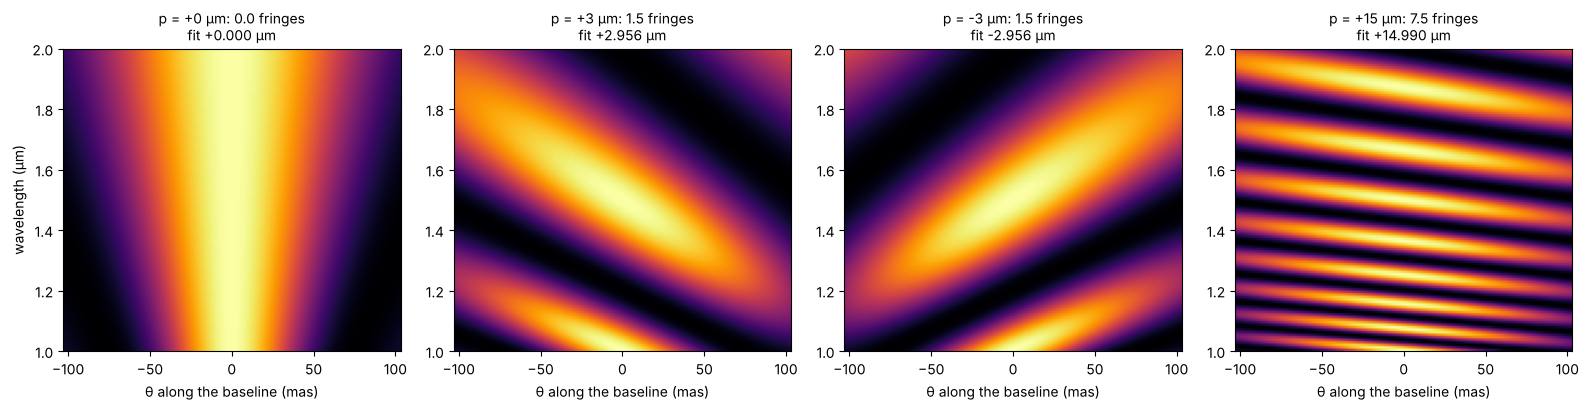

baseline B = 1.327 m


In [10]:
x2 = pupil_grid(256, 6.8)
P2 = sg.jwst_like_pupil(x2, x2)
wl = np.linspace(1.0e-6, 2.0e-6, 120)
th_d = np.linspace(-0.5, 0.5, 101)*1e-6
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, p in zip(axs, (0.0, 3e-6, -3e-6, 15e-6)):
    I, B = sg.dispersed_fringes(P2, x2, x2, p, wl, th_d)
    ax.imshow(I, extent=(th_d[0]/mas, th_d[-1]/mas, wl[0]*1e6, wl[-1]*1e6), origin="lower",
              aspect="auto", cmap="inferno")
    est = sg.dfs_piston(I, wl, th_d, B, 40e-6) if p != 0 else 0.0
    n_fr = abs(p)*(1/wl[0] - 1/wl[-1])
    ax.set_title("p = %+.0f µm: %.1f fringes\nfit %+.3f µm" % (p*1e6, n_fr, est*1e6), fontsize=10)
    ax.set_xlabel("θ along the baseline (mas)")
axs[0].set_ylabel("wavelength (µm)")
plt.tight_layout()
plt.show()
print("baseline B = %.3f m" % B)

How far does it reach? Two effects limit the range. A spectral channel
has a finite width $\delta\sigma$ in wavenumber; the fringe phase changes
by $2\pi p\,\delta\sigma$ across it, and averaging over the channel reduces
the fringe visibility to $\operatorname{sinc}(p\,\delta\sigma) =
\sin(\pi p\,\delta\sigma)/(\pi p\,\delta\sigma)$. And with channels equally
spaced by $\delta\sigma$, the pistons $p$ and $p + 1/\delta\sigma$ produce the
same pattern (up to a common phase): the measurement is unique only for
$|p| < 1/(2\delta\sigma)$. Below, 60 channels equally spaced in wavenumber
over 1–2 µm, each integrating over its width, with 2 % detector noise,
and the search limited to $\pm 1/(2\delta\sigma)$:

channel width 8475 1/m, unique range +-59.0 µm, visibility zero at 118.0 µm


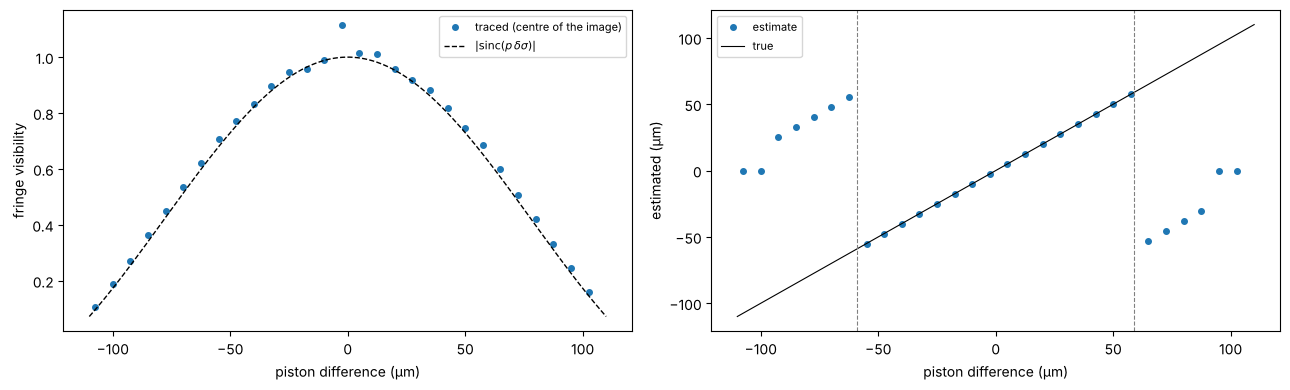

inside the range: rms error 0.017 µm, largest 0.052 µm


In [11]:
sig_ch = np.linspace(0.5e6, 1.0e6, 60)          # wavenumbers 1/m, 1-2 µm
w_ch = 1/sig_ch
d_sig = sig_ch[1] - sig_ch[0]
p_lim = 1/(2*d_sig)
print("channel width %.0f 1/m, unique range +-%.1f µm, visibility zero at %.1f µm"
      % (d_sig, p_lim*1e6, 1/d_sig*1e6))
p_true = np.arange(-107.5, 110, 7.5)*1e-6         # avoids 0 and +-1/(2 dsigma)
vis, est = [], []
for p in p_true:
    I, B = sg.dispersed_fringes(P2, x2, x2, p, w_ch, th_d, n_sub=4)
    c = I[:, len(th_d)//2]
    vis.append(2*np.abs(np.mean((c - c.mean())*np.exp(-2j*np.pi*p*sig_ch)))/np.mean(c))
    I = I + rng.normal(0, 0.02*I.max(), I.shape)
    est.append(sg.dfs_piston(I, w_ch, th_d, B, p_lim, n=1201))
vis, est = np.array(vis), np.array(est)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
pp = np.linspace(-110, 110, 400)*1e-6
axs[0].plot(p_true*1e6, vis, "o", ms=4, label="traced (centre of the image)")
axs[0].plot(pp*1e6, np.abs(np.sinc(pp*d_sig)), "k--", lw=1, label=r"$|\mathrm{sinc}(p\,\delta\sigma)|$")
axs[0].set_xlabel("piston difference (µm)")
axs[0].set_ylabel("fringe visibility")
axs[0].legend(fontsize=8)
axs[1].plot(p_true*1e6, est*1e6, "o", ms=4, label="estimate")
axs[1].plot(pp*1e6, pp*1e6, "k-", lw=0.8, label="true")
for sgn in (1, -1):
    axs[1].axvline(sgn*p_lim*1e6, color="0.5", ls="--", lw=0.8)
axs[1].set_xlabel("piston difference (µm)")
axs[1].set_ylabel("estimated (µm)")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
inside = np.abs(p_true) < 0.9*p_lim
print("inside the range: rms error %.3f µm, largest %.3f µm"
      % (np.sqrt(np.mean((est - p_true)[inside]**2))*1e6, np.max(np.abs(est - p_true)[inside])*1e6))

Inside the unique range the estimate is good to a few tens of
nanometres; beyond it the pattern aliases and the estimate is off by
$1/\delta\sigma$, or meaningless where the visibility approaches its first
zero at $1/\delta\sigma$. A grism of higher spectral resolution reaches
correspondingly larger steps. Coarse phasing has to bring the segments
to within a fraction of a wavelength, the starting point for phase
retrieval.

## 6. Fine phasing by phase retrieval

With all pistons below $\lambda/2$ the pupil phase is unique, and it can be
computed from images. A single in-focus image does not determine it (a
phase and its conjugate rotated by 180° give the same image), but images
with known defocus do. JWST records images through weak lenses of $\pm 8$
waves of defocus at about 2 µm (NIRCam's weak lenses of +8, −8 and +4
waves). From the measured images
the multi-plane Gerchberg–Saxton (Misell) iteration (`misell()`) estimates
the pupil field: transform to each image plane with its diversity phase,
replace the modulus by the measured one, transform back, remove the
diversity, average, impose the known pupil amplitude. A least squares fit
of a plane to each segment (`fit_segments()`) gives the piston and
tip-tilt commands. The retrieval runs on a 128 sample pupil and Nyquist
sampled images.

phase retrieval: 2.8 s
piston: true rms 98.6 nm, error rms 2.35 nm
tip-tilt: true rms 10.20 mas, error rms 0.36 mas


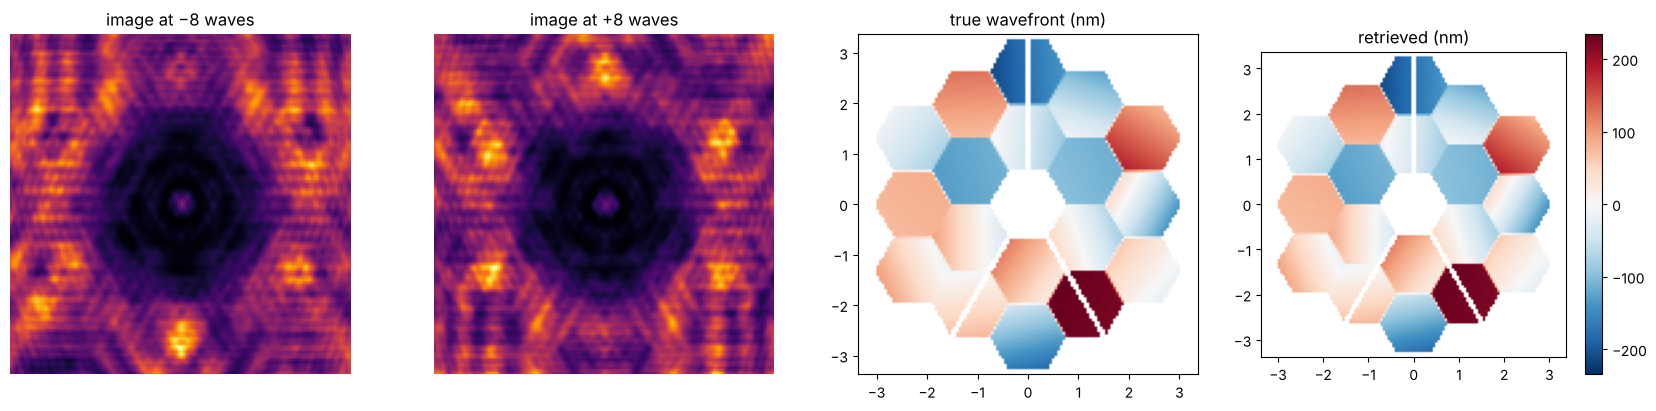

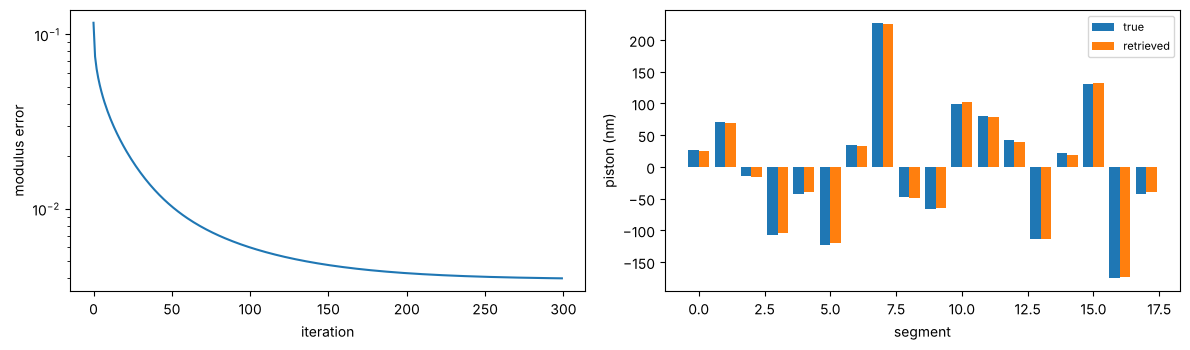

In [12]:
x3 = pupil_grid(128, 6.8)
P3 = sg.jwst_like_pupil(x3, x3)
D3 = 6.6
rng_pr = np.random.default_rng(7)
p0 = rng_pr.normal(0, 150e-9, n_seg)
a0, b0 = rng_pr.normal(0, 10*mas, n_seg), rng_pr.normal(0, 10*mas, n_seg)
E = sg.segment_field(P3, x3, x3, lam, p0, a0, b0)
psfs, phases = sg.diversity_psfs(E, [-8, 8], D3, x3, x3)
t0 = time.time()
phase, err = sg.misell(psfs, phases, P3.pupil, 300)
print("phase retrieval: %.1f s" % (time.time() - t0))
pf, af, bf = sg.fit_segments(phase, P3, x3, x3, lam)
d = (pf - p0) - np.average(pf - p0, weights=(P3.masks*P3.struts).sum((1, 2)))
print("piston: true rms %.1f nm, error rms %.2f nm" % (np.std(p0)*1e9, np.std(d)*1e9))
print("tip-tilt: true rms %.2f mas, error rms %.2f mas"
      % (np.sqrt(np.mean(a0**2 + b0**2)/2)/mas, np.sqrt(np.mean((af - a0)**2 + (bf - b0)**2)/2)/mas))

fig, axs = plt.subplots(1, 4, figsize=(17, 4))
ext3 = (x3[0], x3[-1], x3[0], x3[-1])
for ax, img, title in ((axs[0], psfs[0], "image at −8 waves"), (axs[1], psfs[1], "image at +8 waves")):
    ax.imshow(np.fft.fftshift(img)[64:192, 64:192], cmap="inferno")
    ax.set_title(title)
    ax.axis("off")
true_phase = np.where(P3.pupil > 0.5, np.angle(E*np.exp(-1j*np.angle(np.sum(E)))), np.nan)
ret = np.where(P3.pupil > 0.5, phase, np.nan)
v = np.nanmax(np.abs(true_phase))
axs[2].imshow(true_phase*lam/(2*np.pi)*1e9, extent=ext3, origin="lower", cmap="RdBu_r",
              vmin=-v*lam/(2*np.pi)*1e9, vmax=v*lam/(2*np.pi)*1e9)
axs[2].set_title("true wavefront (nm)")
im = axs[3].imshow(ret*lam/(2*np.pi)*1e9, extent=ext3, origin="lower", cmap="RdBu_r",
                   vmin=-v*lam/(2*np.pi)*1e9, vmax=v*lam/(2*np.pi)*1e9)
axs[3].set_title("retrieved (nm)")
plt.colorbar(im, ax=axs[3])
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].semilogy(err)
axs[0].set_xlabel("iteration")
axs[0].set_ylabel("modulus error")
idx = np.arange(n_seg)
axs[1].bar(idx - 0.2, (p0 - p0.mean())*1e9, 0.4, label="true")
axs[1].bar(idx + 0.2, (pf - pf.mean())*1e9, 0.4, label="retrieved")
axs[1].set_xlabel("segment")
axs[1].set_ylabel("piston (nm)")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The retrieval recovers the pistons (about 100 nm rms) to a few nanometres
and the tilts to a few per cent. The
residual modulus error that the iteration converges to comes from the
pixels on segment edges, where the sampled field of two segments
partly cancels. Applying the fitted corrections and measuring again
closes the loop; each pass multiplies the error by a small factor:

In [13]:
cur_p, cur_a, cur_b = p0.copy(), a0.copy(), b0.copy()
A3 = (P3.masks*P3.struts).sum((1, 2))
E_ref = sg.segment_field(P3, x3, x3, lam)


def strehl(Ec):
    F = np.fft.fft2(Ec, s=(256, 256))
    return np.abs(F).max()**2/np.abs(np.fft.fft2(E_ref, s=(256, 256))).max()**2


hist = []
for it in range(4):
    E = sg.segment_field(P3, x3, x3, lam, cur_p, cur_a, cur_b)
    sp = np.sqrt(np.average((cur_p - np.average(cur_p, weights=A3))**2, weights=A3))
    hist.append((it, sp*1e9, np.sqrt(np.mean(cur_a**2 + cur_b**2)/2)/mas, strehl(E)))
    psfs, phases = sg.diversity_psfs(E, [-8, 8], D3, x3, x3)
    phase, _ = sg.misell(psfs, phases, P3.pupil, 200)
    pf, af, bf = sg.fit_segments(phase, P3, x3, x3, lam)
    cur_p, cur_a, cur_b = cur_p - pf, cur_a - af, cur_b - bf
print("%5s %16s %18s %10s" % ("pass", "piston rms (nm)", "tip-tilt rms (mas)", "Strehl"))
for h in hist:
    print("%5d %16.2f %18.3f %10.4f" % h)

 pass  piston rms (nm) tip-tilt rms (mas)     Strehl
    0            97.45             10.204     0.9049
    1             5.41              0.700     0.9997
    2             1.54              0.199     1.0000
    3             0.46              0.060     1.0000


### Why coarse phasing first

Phase retrieval sees the phase modulo $2\pi$. A segment that is off by
$0.8\lambda$ looks exactly like one that is off by $-0.2\lambda$; the
retrieved piston is wrapped into $(-\lambda/2, \lambda/2]$, and correcting
it leaves the segment a whole wavelength out. At one wavelength the
images are perfect (the Strehl ratio is 1), but at any other wavelength
the step shows. Segment 5 with a piston of $0.8\lambda$:

In [14]:
p_w = np.zeros(n_seg)
p_w[5] = 0.8*lam
E = sg.segment_field(P3, x3, x3, lam, p_w)
psfs, phases = sg.diversity_psfs(E, [-8, 8], D3, x3, x3)
phase, _ = sg.misell(psfs, phases, P3.pupil, 200)
pf, _, _ = sg.fit_segments(phase, P3, x3, x3, lam)
pf -= np.median(pf)
print("segment 5: true piston %.3f lambda, retrieved %.3f lambda" % (p_w[5]/lam, pf[5]/lam))
after = p_w - pf
print("after correction: %.3f lambda" % (after[5]/lam))
for wl_ in (1.5e-6, 2.0e-6, 2.5e-6):
    S_ = np.abs(np.sum(A3*np.exp(2j*np.pi*(after - after.mean())/wl_)))**2/A3.sum()**2
    print("  Strehl at %.1f µm: %.3f" % (wl_*1e6, S_))

segment 5: true piston 0.800 lambda, retrieved -0.196 lambda
after correction: 0.996 lambda
  Strehl at 1.5 µm: 0.841
  Strehl at 2.0 µm: 1.000
  Strehl at 2.5 µm: 0.924


This is why the dispersed fringe sensor (or a broadband image, or phase
retrieval at two wavelengths) has to bring every segment within a
fraction of a wavelength before the fine phasing starts.

## Summary

- The far field of a hexagon is a sum of six edge terms; its six spikes
  point along the edge normals and decay as $u^{-2}$ while the rest decays
  as $u^{-4}$ (closed form against the MFT to $10^{-4}$).
- The phased aperture is the segment PSF times the array factor (exact
  without struts); the struts add spikes perpendicular to themselves, on
  top of the hexagon spikes for the lower two, horizontal for the upper
  one.
- Piston and tip-tilt errors: the Strehl ratio is a phasor sum over the
  segments (exact), close to $e^{-\sigma^2}$; random pistons move light into
  a halo shaped like one segment's PSF.
- The dispersed fringe sensor measures piston steps of micrometres to
  tens of micrometres from the number and tilt of fringes across the
  spectrum, up to $1/(2\delta\sigma)$.
- Phase retrieval from defocused images measures the remaining errors to
  nanometres, modulo a wavelength.

## References

- J. Nelson and G. Chanan, "The W. M. Keck Telescope segmented primary
  mirror active control system", Proc. SPIE 1236, 998–1006 (1990).
- G. Chanan, M. Troy, F. Dekens, S. Michaels, J. Nelson, T. Mast and D.
  Kirkman, "Phasing the mirror segments of the Keck telescopes: the
  broadband phasing algorithm", Appl. Opt. 37, 140–155 (1998).
- F. Shi, D. C. Redding, A. E. Lowman et al., "Segmented mirror coarse
  phasing with a dispersed fringe sensor: experiment on NGST's wavefront
  control testbed", Proc. SPIE 4850, 318–328 (2003).
- D. S. Acton, J. S. Knight, A. Contos et al., "Wavefront sensing and
  controls for the James Webb Space Telescope", Proc. SPIE 8442, 84422H
  (2012).
- D. L. Misell, "An examination of an iterative method for the solution
  of the phase problem in optics and electron optics", J. Phys. D 6,
  2200–2216 (1973).
- S.-W. Lee and R. Mittra, "Fourier transform of a polygonal shape
  function and its application in electromagnetics", IEEE Trans. Antennas
  Propag. 31, 99–103 (1983).

In [15]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 81 s
